Use the GPU execution instead of the CPU.

In [ ]:
import tensorflow as tf
print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Import the dataset from kaggle.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cifake-real-and-ai-generated-synthetic-images' dataset.
Path to dataset files: /kaggle/input/cifake-real-and-ai-generated-synthetic-images


In [ ]:
!rm -f "/content/ai-image-detector-data.zip" "/content/archive (5).zip"

DATA_DIR = path   # le chemin renvoyé par kagglehub
print(DATA_DIR)

/kaggle/input/cifake-real-and-ai-generated-synthetic-images


Verify the dataset structure and content.

In [ ]:
import os

for root, dirs, files_ in os.walk(DATA_DIR):
    depth = root.replace(DATA_DIR, "").count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(root) + "/", f"({len(files_)} fichiers)" if files_ else "")

cifake-real-and-ai-generated-synthetic-images/ 
  test/ 
    FAKE/ (10000 fichiers)
    REAL/ (10000 fichiers)
  train/ 
    FAKE/ (50000 fichiers)
    REAL/ (50000 fichiers)


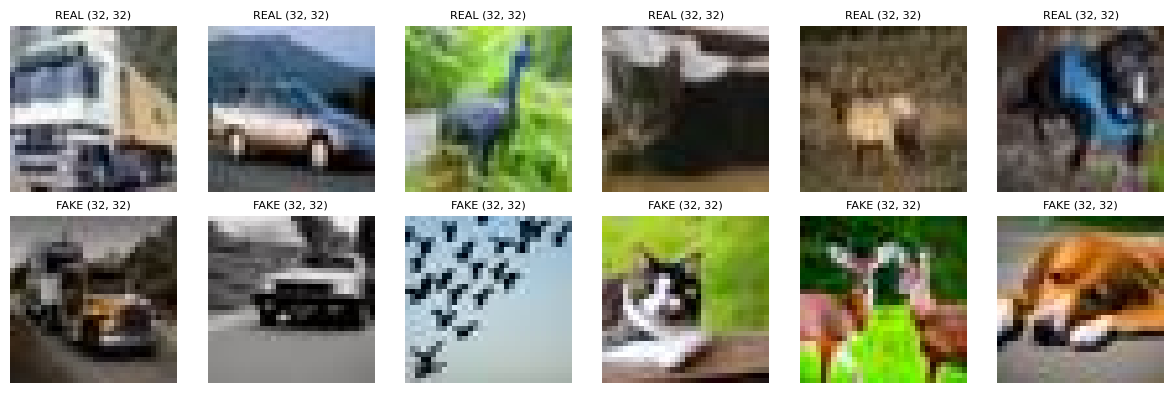

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i, label in enumerate(["REAL", "FAKE"]):
    folder = os.path.join(DATA_DIR, "train", label)
    for j, name in enumerate(sorted(os.listdir(folder))[:6]):
        img = Image.open(os.path.join(folder, name))
        axes[i][j].imshow(img)
        axes[i][j].axis("off")
        axes[i][j].set_title(f"{label} {img.size}", fontsize=8)
plt.tight_layout()
plt.show()

# Phase 2: Preprocessing


1.   Goal: clean data, a train/validation/test split with no leakage, and a tf.data pipeline ready for EfficientNetB0. Each block is one code cell.



The dataset folder is a slow read-only mount, so before preprocessing we copy it to Colab’s local disk. That makes every later step, and the training, much faster.

In [ ]:
!cp -r "{DATA_DIR}" /content/cifake
DATA_DIR = "/content/cifake"

import os
print(os.listdir(DATA_DIR))   # should show ['train', 'test']

['test', 'train']


# Build a DataFrame of all images

In [ ]:
import pandas as pd
from tqdm.auto import tqdm

rows = []
for split in ["train", "test"]:
    for label in ["FAKE", "REAL"]:
        folder = os.path.join(DATA_DIR, split, label)
        for name in os.listdir(folder):
            rows.append({"path": os.path.join(folder, name), "split": split, "class": label})

df = pd.DataFrame(rows)
df["label"] = (df["class"] == "REAL").astype(int)   # FAKE = 0, REAL = 1 (same as Keras)
print(df.shape)
df.head()

(120000, 4)


,path,split,class,label
0,/content/cifake/train/FAKE/1537 (4).jpg,train,FAKE,0
1,/content/cifake/train/FAKE/1600.jpg,train,FAKE,0
2,/content/cifake/train/FAKE/3821 (8).jpg,train,FAKE,0
3,/content/cifake/train/FAKE/3066 (10).jpg,train,FAKE,0
4,/content/cifake/train/FAKE/4045 (4).jpg,train,FAKE,0


# Detect corrupted images and check formats

In [ ]:
from PIL import Image

def check(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            return True, im.size, im.mode
    except Exception:
        return False, None, None

results = [check(p) for p in tqdm(df["path"])]
df["valid"] = [r[0] for r in results]
df["size"]  = [r[1] for r in results]
df["mode"]  = [r[2] for r in results]

print("Valid images :", df["valid"].sum(), "/", len(df))
print(df["size"].value_counts())
print(df["mode"].value_counts())

  0%|          | 0/120000 [00:00<?, ?it/s]

Valid images : 120000 / 120000
size
(32, 32)    120000
Name: count, dtype: int64
mode
RGB    120000
Name: count, dtype: int64


# Detect duplicates and train/test leakage

In [ ]:
import hashlib

def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = [md5(p) for p in tqdm(df["path"])]

tr, te = df[df.split == "train"], df[df.split == "test"]
print("Duplicates inside train :", tr.duplicated("md5").sum())
print("Duplicates inside test  :", te.duplicated("md5").sum())
print("Train/test overlap      :", len(set(tr.md5) & set(te.md5)))

  0%|          | 0/120000 [00:00<?, ?it/s]

Duplicates inside train : 920
Duplicates inside test  : 38
Train/test overlap      : 378


# Clean the data

In [ ]:
n0 = len(df)
df_clean = df[df.valid].copy()
df_clean = df_clean.drop_duplicates(subset=["split", "md5"], keep="first")

test_hashes = set(df_clean[df_clean.split == "test"].md5)
leak = (df_clean.split == "train") & (df_clean.md5.isin(test_hashes))
df_clean = df_clean[~leak]

print(f"Removed {n0 - len(df_clean)} images ({n0} -> {len(df_clean)})")

Removed 1336 images (120000 -> 118664)


# Check class balance and create the validation set

In [ ]:
from sklearn.model_selection import train_test_split

train_all = df_clean[df_clean.split == "train"]
train_df, val_df = train_test_split(
    train_all, test_size=0.2, stratify=train_all["label"], random_state=42)
test_df = df_clean[df_clean.split == "test"]

summary = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "total": [len(train_df), len(val_df), len(test_df)],
    "FAKE (0)": [(d.label == 0).sum() for d in (train_df, val_df, test_df)],
    "REAL (1)": [(d.label == 1).sum() for d in (train_df, val_df, test_df)],
})
print(summary)

          set  total  FAKE (0)  REAL (1)
0       train  78961     38961     40000
1  validation  19741      9741     10000
2        test  19962      9962     10000


# Build the tf.data pipeline

In [ ]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)          # bilinear, values stay in 0-255
    return img, tf.cast(label, tf.float32)

def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values))
    if shuffle:
        ds = ds.shuffle(len(d), seed=42)
    return ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# Verify the pipeline we've created.

Images : (64, 128, 128, 3) <dtype: 'float32'>
Labels : (64,) <dtype: 'float32'>
Pixel range : 0.0 - 255.0


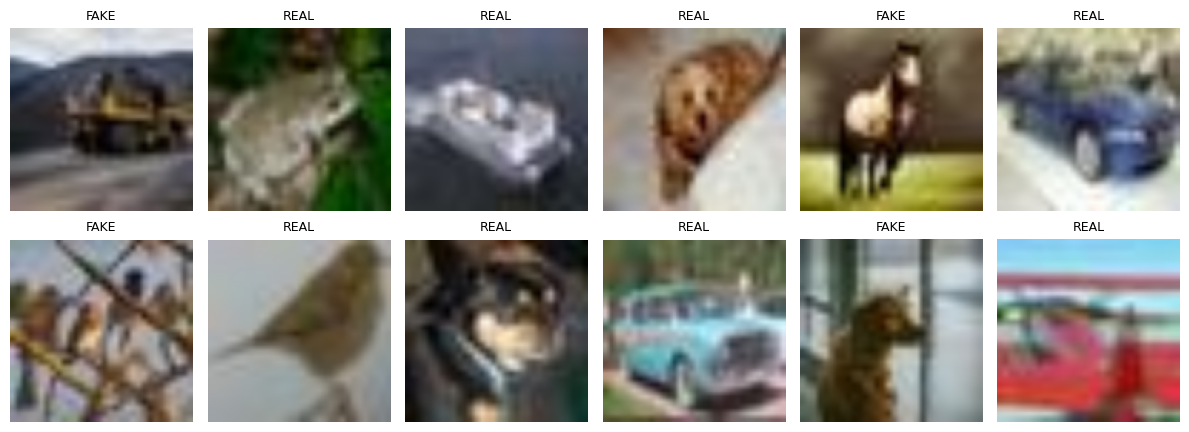

In [ ]:
x, y = next(iter(train_ds))
print("Images :", x.shape, x.dtype)
print("Labels :", y.shape, y.dtype)
print("Pixel range :", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, lab in zip(axes.ravel(), x[:12], y[:12]):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title("REAL" if lab == 1 else "FAKE", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

# Exploration and visualization
Goal: understand the data with charts and statistics, and produce figures for the report. This phase goes in the same notebook. Each block is one cell.
1. Class distribution

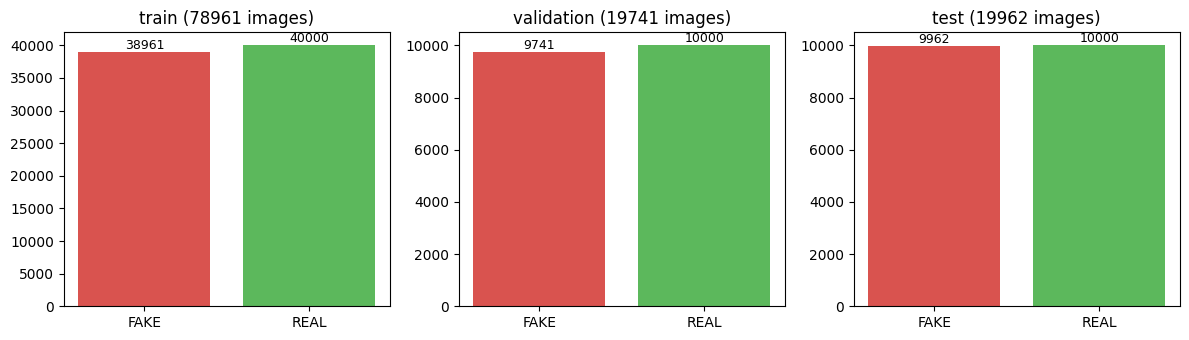

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image

os.makedirs("figures", exist_ok=True)

sets = {"train": train_df, "validation": val_df, "test": test_df}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)
for ax, (name, d) in zip(axes, sets.items()):
    counts = d["class"].value_counts().reindex(["FAKE", "REAL"])
    ax.bar(counts.index, counts.values, color=["#d9534f", "#5cb85c"])
    ax.set_title(f"{name} ({len(d)} images)")
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("figures/01_class_distribution.png", dpi=150)
plt.show()

2. Examples at original resolution

We use the original 32x32 images, not the enlarged ones.

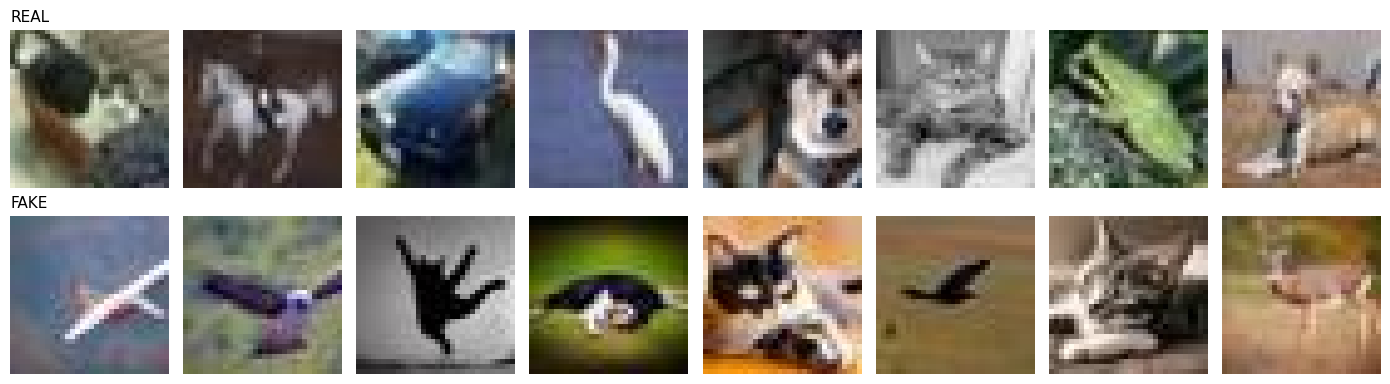

In [ ]:
def show_examples(cls, n=8, seed=0):
    sub = train_df[train_df["class"] == cls].sample(n, random_state=seed)
    return [Image.open(p).convert("RGB") for p in sub["path"]]

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, cls in enumerate(["REAL", "FAKE"]):
    for j, img in enumerate(show_examples(cls)):
        axes[i][j].imshow(img, interpolation="nearest")
        axes[i][j].axis("off")
    axes[i][0].set_title(cls, loc="left", fontsize=11)
plt.tight_layout()
plt.savefig("figures/02_examples.png", dpi=150)
plt.show()

Step 3: Load a sample for the statistics

Loading 3,000 images per class is enough for stable statistics and runs quickly.

In [ ]:
def load_sample(cls, n=3000):
    paths = train_df[train_df["class"] == cls]["path"].sample(n, random_state=42).values
    return np.stack([np.array(Image.open(p).convert("RGB")) for p in paths]).astype("float32")

real = load_sample("REAL")
fake = load_sample("FAKE")
print(real.shape, fake.shape)   # (3000, 32, 32, 3)

(3000, 32, 32, 3) (3000, 32, 32, 3)


Step 4: Pixel statistics and histograms

  class      mean_R      mean_G      mean_B  std (all channels)
0  REAL  125.070000  122.680000  114.029999           63.919998
1  FAKE  114.940002  112.809998   99.629997           62.520000


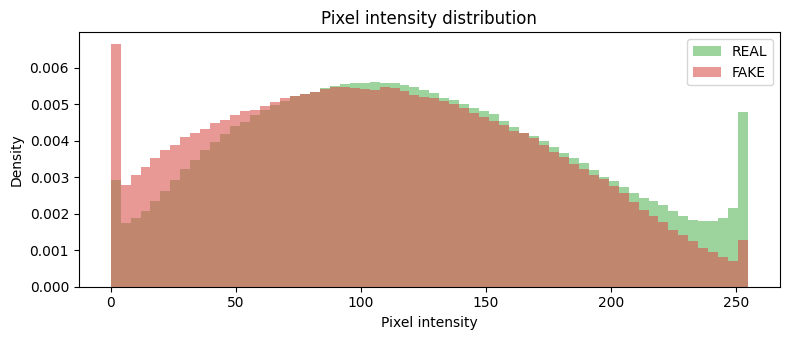

In [ ]:
import pandas as pd

stats = pd.DataFrame({
    "class": ["REAL", "FAKE"],
    "mean_R": [real[..., 0].mean(), fake[..., 0].mean()],
    "mean_G": [real[..., 1].mean(), fake[..., 1].mean()],
    "mean_B": [real[..., 2].mean(), fake[..., 2].mean()],
    "std (all channels)": [real.std(), fake.std()],
})
print(stats.round(2))

plt.figure(figsize=(8, 3.5))
plt.hist(real.ravel(), bins=64, range=(0, 255), alpha=0.6, density=True, label="REAL", color="#5cb85c")
plt.hist(fake.ravel(), bins=64, range=(0, 255), alpha=0.6, density=True, label="FAKE", color="#d9534f")
plt.xlabel("Pixel intensity"); plt.ylabel("Density"); plt.legend()
plt.title("Pixel intensity distribution")
plt.tight_layout()
plt.savefig("figures/03_pixel_histogram.png", dpi=150)
plt.show()

Step 5: Mean image per class

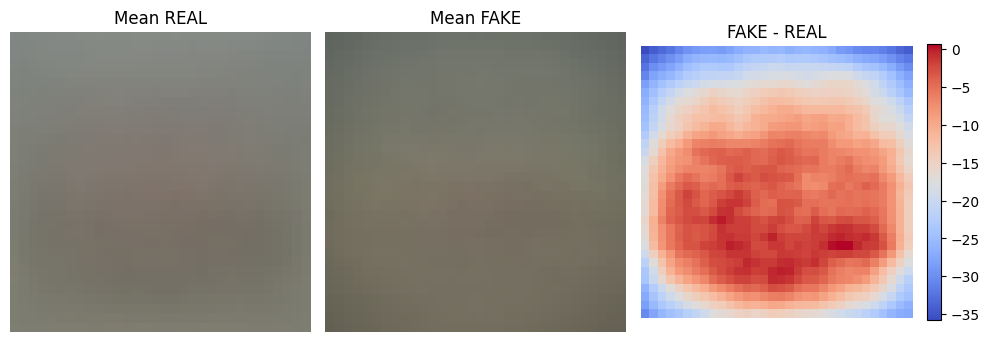

In [ ]:
mean_real, mean_fake = real.mean(axis=0), fake.mean(axis=0)
diff = mean_fake.mean(axis=-1) - mean_real.mean(axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(mean_real.astype("uint8")); axes[0].set_title("Mean REAL")
axes[1].imshow(mean_fake.astype("uint8")); axes[1].set_title("Mean FAKE")
im = axes[2].imshow(diff, cmap="coolwarm"); axes[2].set_title("FAKE - REAL")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for a in axes: a.axis("off")
plt.tight_layout()
plt.savefig("figures/04_mean_images.png", dpi=150)
plt.show()

Step 6: Average Fourier spectrum per class

This shows how energy is distributed across spatial frequencies. Generated images sometimes show differences here, but at 32x32 the differences may be subtle or absent, so report what you actually see.

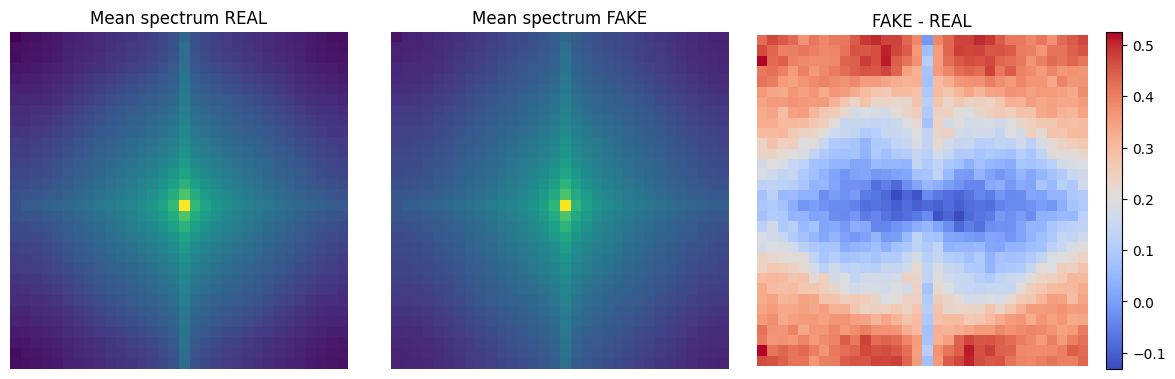

In [ ]:
def mean_spectrum(arr):
    gray = arr.mean(axis=-1)                                   # (n, 32, 32)
    f = np.fft.fftshift(np.fft.fft2(gray), axes=(-2, -1))
    return np.log1p(np.abs(f)).mean(axis=0)

spec_real, spec_fake = mean_spectrum(real), mean_spectrum(fake)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
vmin, vmax = min(spec_real.min(), spec_fake.min()), max(spec_real.max(), spec_fake.max())
axes[0].imshow(spec_real, cmap="viridis", vmin=vmin, vmax=vmax); axes[0].set_title("Mean spectrum REAL")
axes[1].imshow(spec_fake, cmap="viridis", vmin=vmin, vmax=vmax); axes[1].set_title("Mean spectrum FAKE")
im = axes[2].imshow(spec_fake - spec_real, cmap="coolwarm"); axes[2].set_title("FAKE - REAL")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for a in axes: a.axis("off")
plt.tight_layout()
plt.savefig("figures/05_fourier_spectrum.png", dpi=150)
plt.show()

This cell trains a tiny classifier using only simple brightness features. It gives you a baseline to compare against EfficientNetB0 and tells you how much of the task these statistics already solve.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

def feats(arr):
    flat = arr.reshape(len(arr), -1)
    return np.column_stack([
        arr.mean(axis=(1, 2)),       # mean per channel (3)
        arr.std(axis=(1, 2)),        # std per channel (3)
        (flat == 0).mean(axis=1),    # fraction of pure black values
        (flat >= 255).mean(axis=1),  # fraction of pure white values
    ])

X = np.vstack([feats(real), feats(fake)])
y = np.r_[np.ones(len(real)), np.zeros(len(fake))]

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(clf, X, y, cv=5, scoring="accuracy")
print("Brightness-only accuracy: %.3f (+/- %.3f)" % (scores.mean(), scores.std()))

Brightness-only accuracy: 0.668 (+/- 0.017)


# Phase 4: building and training EfficientNetB0


1.   Goal: train EfficientNetB0 following your professor’s 7-step pipeline, first feature extraction (steps 1 to 5), then fine-tuning (steps 6 and 7). We do not touch the test set here. It is reserved for the evaluation in phase 5.




In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# Pipeline 1-2: pretrained model without the final ImageNet layer
base = EfficientNetB0(include_top=False, weights="imagenet",
                      input_shape=(128, 128, 3))

# Pipeline 3: freeze the base
base.trainable = False

# Pipeline 4: new classifier
inputs = tf.keras.Input(shape=(128, 128, 3))
x = layers.RandomFlip("horizontal")(inputs)    # augmentation, only active during training
x = base(x, training=False)                    # BatchNorm layers stay in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)   # probability of REAL (1)
model = models.Model(inputs, outputs, name="effnetb0_detector")

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "effnetb0_detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

train the classifier

In [ ]:
import time
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

callbacks_p1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
    tf.keras.callbacks.ModelCheckpoint("/content/ckpt_phase1.keras",
                                       monitor="val_loss", save_best_only=True),
]

t0 = time.time()
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks_p1)
time_p1 = time.time() - t0
print(f"Phase 1 training time: {time_p1/60:.1f} min")

val_metrics_p1 = model.evaluate(val_ds, return_dict=True)
print("Validation after feature extraction:", val_metrics_p1)

Epoch 1/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 104s 58ms/step - accuracy: 0.8313 - auc: 0.9133 - loss: 0.3801 - val_accuracy: 0.8804 - val_auc: 0.9515 - val_loss: 0.2941 - learning_rate: 0.0010
Epoch 2/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 93s 35ms/step - accuracy: 0.8582 - auc: 0.9353 - loss: 0.3260 - val_accuracy: 0.8883 - val_auc: 0.9562 - val_loss: 0.2754 - learning_rate: 0.0010
Epoch 3/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 42s 34ms/step - accuracy: 0.8613 - auc: 0.9366 - loss: 0.3219 - val_accuracy: 0.8920 - val_auc: 0.9581 - val_loss: 0.2689 - learning_rate: 0.0010
Epoch 4/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 39s 32ms/step - accuracy: 0.8622 - auc: 0.9372 - loss: 0.3201 - val_accuracy: 0.8918 - val_auc: 0.9589 - val_loss: 0.2655 - learning_rate: 0.0010
Epoch 5/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.8634 - auc: 0.9384 - loss: 0.3171 - val_accuracy: 0.8942 - val_auc: 0.9593 - val_loss: 0.2639 - learning_rate: 0.0010
Epoch 6/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 39s 32ms/step - a

* EarlyStopping stops when validation loss hasn’t improved for 3 epochs and restores the best weights.
* ModelCheckpoint saves the best version to disk in case Colab disconnects.


fine-tuning

In [ ]:
# Pipeline 6: unfreeze the last 20 layers of the base (BatchNorm layers stay frozen)
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False
for layer in base.layers[-20:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
print("Trainable parameters after unfreezing:", n_trainable)

# Pipeline 7: recompile with a small learning rate (mandatory after changing trainable)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

callbacks_p2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("/content/ckpt_phase2.keras",
                                       monitor="val_loss", save_best_only=True),
]

t0 = time.time()
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks_p2)
time_p2 = time.time() - t0
print(f"Fine-tuning time: {time_p2/60:.1f} min")

val_metrics_p2 = model.evaluate(val_ds, return_dict=True)
print("Validation after fine-tuning:", val_metrics_p2)

Trainable parameters after unfreezing: 1344049
Epoch 1/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 100s 57ms/step - accuracy: 0.8885 - auc: 0.9571 - loss: 0.2655 - val_accuracy: 0.9257 - val_auc: 0.9780 - val_loss: 0.1901
Epoch 2/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 46s 37ms/step - accuracy: 0.9144 - auc: 0.9727 - loss: 0.2111 - val_accuracy: 0.9381 - val_auc: 0.9837 - val_loss: 0.1627
Epoch 3/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 42s 34ms/step - accuracy: 0.9284 - auc: 0.9800 - loss: 0.1802 - val_accuracy: 0.9443 - val_auc: 0.9867 - val_loss: 0.1461
Epoch 4/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 46s 37ms/step - accuracy: 0.9359 - auc: 0.9838 - loss: 0.1614 - val_accuracy: 0.9479 - val_auc: 0.9884 - val_loss: 0.1358
Epoch 5/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 83s 38ms/step - accuracy: 0.9421 - auc: 0.9860 - loss: 0.1495 - val_accuracy: 0.9516 - val_auc: 0.9898 - val_loss: 0.1270
Epoch 6/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 80s 36ms/step - accuracy: 0.9463 - auc: 0.9879 - loss: 0.1380 - val_accuracy: 0.9536 - val

learning curves

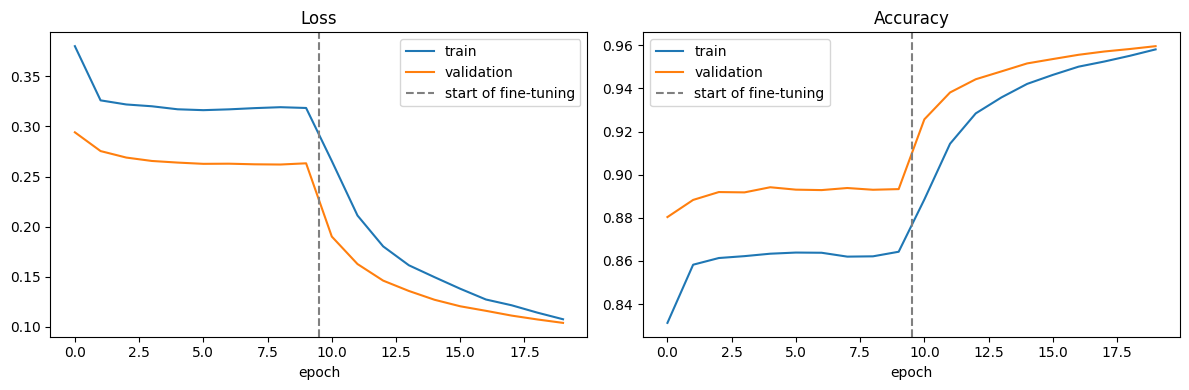

In [ ]:
import matplotlib.pyplot as plt, os

def merge(key):
    return hist1.history[key] + hist2.history[key]

split_at = len(hist1.history["loss"])
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(merge(key), label="train")
    ax.plot(merge("val_" + key), label="validation")
    ax.axvline(split_at - 0.5, color="gray", linestyle="--", label="start of fine-tuning")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.savefig("figures/06_learning_curves.png", dpi=150)
plt.show()

Since the curves are still improving and each round costs about 11 minutes, we recommend continuing the fine-tuning for up to 10 more epochs before touching the test set. The test set should be used once, at the end, so it’s better to finish training first. The optimizer keeps its state if we don’t recompile, so just call fit again:

In [ ]:
callbacks_p3 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("/content/ckpt_phase3.keras",
                                       monitor="val_loss", save_best_only=True),
]

t0 = time.time()
hist3 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks_p3)
time_p3 = time.time() - t0
print(f"Extra fine-tuning time: {time_p3/60:.1f} min")

val_metrics_p3 = model.evaluate(val_ds, return_dict=True)
print("Validation after extra fine-tuning:", val_metrics_p3)

Epoch 1/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 46s 37ms/step - accuracy: 0.9600 - auc: 0.9931 - loss: 0.1041 - val_accuracy: 0.9605 - val_auc: 0.9934 - val_loss: 0.1009
Epoch 2/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 45s 37ms/step - accuracy: 0.9616 - auc: 0.9939 - loss: 0.0979 - val_accuracy: 0.9618 - val_auc: 0.9936 - val_loss: 0.0992
Epoch 3/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 44s 35ms/step - accuracy: 0.9644 - auc: 0.9943 - loss: 0.0939 - val_accuracy: 0.9620 - val_auc: 0.9938 - val_loss: 0.0973
Epoch 4/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 46s 37ms/step - accuracy: 0.9644 - auc: 0.9946 - loss: 0.0917 - val_accuracy: 0.9637 - val_auc: 0.9941 - val_loss: 0.0945
Epoch 5/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 50s 40ms/step - accuracy: 0.9672 - auc: 0.9950 - loss: 0.0867 - val_accuracy: 0.9648 - val_auc: 0.9943 - val_loss: 0.0927
Epoch 6/10
1234/1234 ━━━━━━━━━━━━━━━━━━━━ 78s 37ms/step - accuracy: 0.9678 - auc: 0.9953 - loss: 0.0846 - val_accuracy: 0.9648 - val_auc: 0.9944 - val_loss: 0.0925
Epoch 7/10
1234/

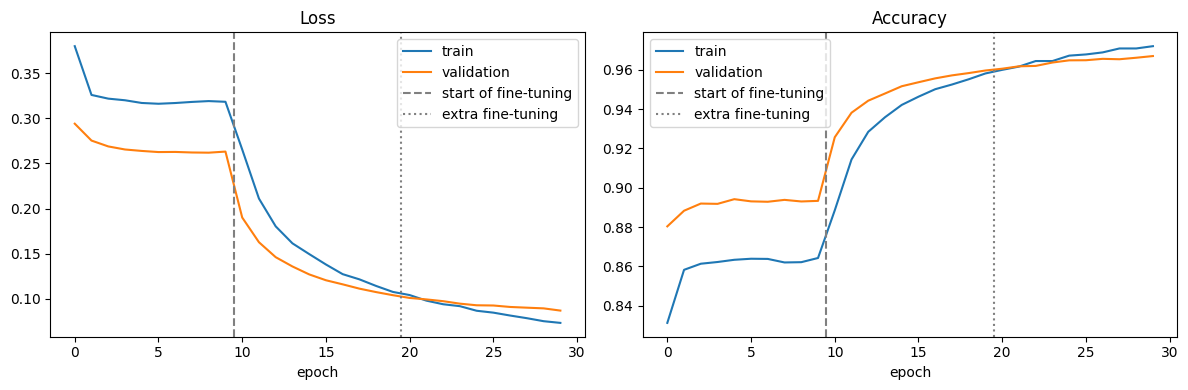

In [ ]:
def merge(key):
    return hist1.history[key] + hist2.history[key] + hist3.history[key]

n1 = len(hist1.history["loss"])
n2 = len(hist2.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(merge(key), label="train")
    ax.plot(merge("val_" + key), label="validation")
    ax.axvline(n1 - 0.5, color="gray", linestyle="--", label="start of fine-tuning")
    ax.axvline(n1 + n2 - 0.5, color="gray", linestyle=":", label="extra fine-tuning")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.savefig("figures/06_learning_curves.png", dpi=150)
plt.show()

Save the model

In [ ]:
model.save("detector.keras")
print("Model size: %.1f MB" % (os.path.getsize("detector.keras") / 1e6))

from google.colab import files
files.download("detector.keras")
files.download("figures/06_learning_curves.png")

Model size: 27.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Phase 5: evaluation on the test set
Goal: measure real performance on the 19,8xx test images, which the model has never used for training or for any decision. Run this once. If we tune the model after looking at the test results, the test set stops being an honest measure.

In [ ]:
import numpy as np

y_prob = model.predict(test_ds).ravel()          # probability of REAL (class 1)
y_true = test_df["label"].values                 # test_ds is not shuffled, so the order matches
y_pred = (y_prob > 0.5).astype(int)

print(len(y_true), len(y_prob))
print("Share of REAL in test:", y_true.mean().round(4))

312/312 ━━━━━━━━━━━━━━━━━━━━ 32s 60ms/step
19962 19962
Share of REAL in test: 0.501


The two lengths are equal

# main metrics

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

print(classification_report(y_true, y_pred, target_names=["FAKE", "REAL"], digits=4))
print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_true, y_prob), 4))
print("Recall on FAKE:", round(recall_score(y_true, y_pred, pos_label=0), 4))

              precision    recall  f1-score   support

        FAKE     0.9629    0.9715    0.9672      9962
        REAL     0.9713    0.9627    0.9670     10000

    accuracy                         0.9671     19962
   macro avg     0.9671    0.9671    0.9671     19962
weighted avg     0.9671    0.9671    0.9671     19962

Accuracy : 0.9671
ROC-AUC  : 0.9953
Recall on FAKE: 0.9715


[[9678  284]
 [ 373 9627]]


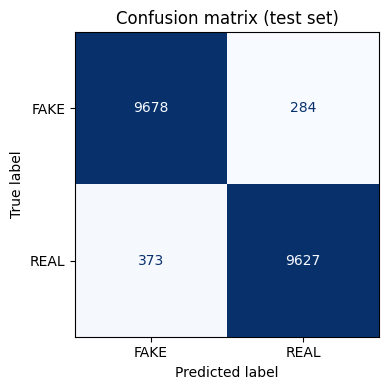

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print(cm)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["FAKE", "REAL"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig("figures/07_confusion_matrix.png", dpi=150)
plt.show()

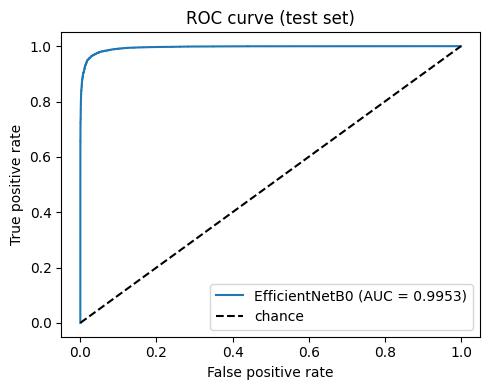

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"EfficientNetB0 (AUC = {roc_auc_score(y_true, y_prob):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve (test set)"); plt.legend()
plt.tight_layout()
plt.savefig("figures/08_roc_curve.png", dpi=150)
plt.show()

In [ ]:
reloaded = tf.keras.models.load_model("detector.keras")

x, y = next(iter(val_ds))
p_original = model.predict(x, verbose=0).ravel()
p_reloaded = reloaded.predict(x, verbose=0).ravel()

print("Max difference:", np.abs(p_original - p_reloaded).max())

Max difference: 0.0
